# Step 2 — Import the libraries

In [2]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import re
import time
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Step 3 — Collect the washing machine listing data

# 3.1 Send the request

In [3]:
url = "https://www.flipkart.com/search?q=washing+machine"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(
    url,
    headers=headers,
    timeout=20
)

print("Status:", response.status_code)

if response.status_code != 200:
    raise RuntimeError("Listing page could not be retrieved.")

soup = BeautifulSoup(response.text, "html.parser")

Status: 200


# 3.2 Extract unique product links

In [4]:
base_url = "https://www.flipkart.com"
products = {}

for a in soup.find_all("a", href=True):
    href = a["href"]

    if "/p/" not in href:
        continue

    full_url = (
        href if href.startswith("http")
        else base_url + href
    )

    # Remove query parameters for deduplication
    full_url = full_url.split("?")[0]

    if full_url not in products:
        products[full_url] = a.get_text(" ", strip=True)

links_df = pd.DataFrame([
    {"URL": url, "Link_Text": name}
    for url, name in products.items()
])

print("Unique product links:", len(links_df))
display(links_df.head(10))

Unique product links: 23


,URL,Link_Text
0,https://www.flipkart.com/whirlpool-7-kg-5-star...,Add to Compare Whirlpool 7 kg 5 Star Inverter ...
1,https://www.flipkart.com/whirlpool-8-kg-fully-...,Add to Compare Whirlpool 8 kg Fully Automatic ...
2,https://www.flipkart.com/samsung-7-kg-5-star-e...,"Add to Compare Samsung 7 kg 5 Star, Ecobubble,..."
3,https://www.flipkart.com/whirlpool-7-kg-magic-...,Add to Compare Whirlpool 7 kg Magic Clean 5 St...
4,https://www.flipkart.com/lg-7-kg-5-star-wind-j...,Add to Compare LG 7 kg 5 Star with Wind Jet Dr...
5,https://www.flipkart.com/realme-techlife-7-5-k...,Add to Compare realme TechLife 7.5 kg with Swi...
6,https://www.flipkart.com/vw-8-5-kg-semi-automa...,Add to Compare VW 8.5 kg Semi-Automatic Top Lo...
7,https://www.flipkart.com/voltas-beko-9-kg-semi...,Add to Compare Voltas Beko 9 kg Semi Automatic...
8,https://www.flipkart.com/lg-8-kg-5-star-smart-...,"Add to Compare LG 8 kg 5 Star, Smart Inverter ..."
9,https://www.flipkart.com/samsung-9-kg-5-star-a...,"Add to Compare Samsung 9 kg 5 Star, AI Ecobubb..."


# 3.3 Inspect the product cards

In [5]:
card_records = []

for a in soup.find_all("a", href=True):
    href = a["href"]

    if "/p/" not in href:
        continue

    # Walk through parent elements to find product information
    node = a
    best_text = a.get_text(" ", strip=True)

    for _ in range(6):
        if node.parent is None:
            break

        node = node.parent
        text = node.get_text(" ", strip=True)

        # Prefer a nearby container containing a price
        if "₹" in text and len(text) < 2000:
            best_text = text
            break

    card_records.append({
        "URL": href if href.startswith("http") else base_url + href,
        "Card_Text": best_text
    })

cards_df = pd.DataFrame(card_records).drop_duplicates(subset="URL")

print("Candidate product cards:", len(cards_df))
display(cards_df.head(5))

Candidate product cards: 29


,URL,Card_Text
0,https://www.flipkart.com/whirlpool-7-kg-5-star...,Add to Compare Whirlpool 7 kg 5 Star Inverter ...
1,https://www.flipkart.com/whirlpool-8-kg-fully-...,Add to Compare Whirlpool 8 kg Fully Automatic ...
2,https://www.flipkart.com/samsung-7-kg-5-star-e...,"Add to Compare Samsung 7 kg 5 Star, Ecobubble,..."
3,https://www.flipkart.com/whirlpool-7-kg-magic-...,Add to Compare Whirlpool 7 kg Magic Clean 5 St...
4,https://www.flipkart.com/lg-7-kg-5-star-wind-j...,Add to Compare LG 7 kg 5 Star with Wind Jet Dr...


# Step 4 — Create your first raw dataset

In [6]:
def extract_price(text):
    # Match prices such as ₹18,990 or ₹1,25,000
    match = re.search(r"₹\s*([\d,]+)", text)

    if match:
        return match.group(1)

    return None


def clean_product_name(text):
    # Remove common comparison-button text
    text = re.sub(r"Add to Compare", "", text, flags=re.I)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


raw_records = []

for _, row in cards_df.iterrows():
    text = row["Card_Text"]

    raw_records.append({
        "Product_Name_Raw": clean_product_name(text),
        "Price_Raw": extract_price(text),
        "URL": row["URL"],
        "Card_Text_Raw": text
    })

raw_df = pd.DataFrame(raw_records)

print("Rows collected:", len(raw_df))
print("Prices found:", raw_df["Price_Raw"].notna().sum())

display(raw_df.head(10))

Rows collected: 29
Prices found: 29


,Product_Name_Raw,Price_Raw,URL,Card_Text_Raw
0,Whirlpool 7 kg 5 Star Inverter 100+ Tough Stai...,"26,290",https://www.flipkart.com/whirlpool-7-kg-5-star...,Add to Compare Whirlpool 7 kg 5 Star Inverter ...
1,Whirlpool 8 kg Fully Automatic Top Load Washin...,"19,990",https://www.flipkart.com/whirlpool-8-kg-fully-...,Add to Compare Whirlpool 8 kg Fully Automatic ...
2,"Samsung 7 kg 5 Star, Ecobubble, Soft Closing D...","17,490",https://www.flipkart.com/samsung-7-kg-5-star-e...,"Add to Compare Samsung 7 kg 5 Star, Ecobubble,..."
3,Whirlpool 7 kg Magic Clean 5 Star Fully Automa...,"15,490",https://www.flipkart.com/whirlpool-7-kg-magic-...,Add to Compare Whirlpool 7 kg Magic Clean 5 St...
4,"LG 7 kg 5 Star with Wind Jet Dry, Collar Scrub...","10,990",https://www.flipkart.com/lg-7-kg-5-star-wind-j...,Add to Compare LG 7 kg 5 Star with Wind Jet Dr...
5,realme TechLife 7.5 kg with Swift Jet Dry Semi...,"7,590",https://www.flipkart.com/realme-techlife-7-5-k...,Add to Compare realme TechLife 7.5 kg with Swi...
6,VW 8.5 kg Semi-Automatic Top Load Washer only ...,"5,010",https://www.flipkart.com/vw-8-5-kg-semi-automa...,Add to Compare VW 8.5 kg Semi-Automatic Top Lo...
7,Voltas Beko 9 kg Semi Automatic Top Load Washi...,"11,740",https://www.flipkart.com/voltas-beko-9-kg-semi...,Add to Compare Voltas Beko 9 kg Semi Automatic...
8,"LG 8 kg 5 Star, Smart Inverter Technology, Tur...","20,990",https://www.flipkart.com/lg-8-kg-5-star-smart-...,"Add to Compare LG 8 kg 5 Star, Smart Inverter ..."
9,"Samsung 9 kg 5 Star, AI Ecobubble, Super Speed...","38,990",https://www.flipkart.com/samsung-9-kg-5-star-a...,"Add to Compare Samsung 9 kg 5 Star, AI Ecobubb..."


# Save the raw dataset

In [7]:
os.makedirs("washing_machine_project", exist_ok=True)

raw_df.to_csv(
    "washing_machine_project/raw_washing_machine_data.csv",
    index=False
)

print("Raw dataset saved successfully!")

Raw dataset saved successfully!


# Step 5: Data Cleaning using Pandas and Regular Expressions (Regex)

# Step 5.1 — Check your raw dataset

In [8]:
print("Dataset shape:", raw_df.shape)

display(raw_df.head(5))

print("\nColumn names:")
print(raw_df.columns.tolist())

print("\nMissing values:")
print(raw_df.isnull().sum())

print("\nDuplicate rows:", raw_df.duplicated().sum())

Dataset shape: (29, 4)


,Product_Name_Raw,Price_Raw,URL,Card_Text_Raw
0,Whirlpool 7 kg 5 Star Inverter 100+ Tough Stai...,"26,290",https://www.flipkart.com/whirlpool-7-kg-5-star...,Add to Compare Whirlpool 7 kg 5 Star Inverter ...
1,Whirlpool 8 kg Fully Automatic Top Load Washin...,"19,990",https://www.flipkart.com/whirlpool-8-kg-fully-...,Add to Compare Whirlpool 8 kg Fully Automatic ...
2,"Samsung 7 kg 5 Star, Ecobubble, Soft Closing D...","17,490",https://www.flipkart.com/samsung-7-kg-5-star-e...,"Add to Compare Samsung 7 kg 5 Star, Ecobubble,..."
3,Whirlpool 7 kg Magic Clean 5 Star Fully Automa...,"15,490",https://www.flipkart.com/whirlpool-7-kg-magic-...,Add to Compare Whirlpool 7 kg Magic Clean 5 St...
4,"LG 7 kg 5 Star with Wind Jet Dry, Collar Scrub...","10,990",https://www.flipkart.com/lg-7-kg-5-star-wind-j...,Add to Compare LG 7 kg 5 Star with Wind Jet Dr...



Column names:
['Product_Name_Raw', 'Price_Raw', 'URL', 'Card_Text_Raw']

Missing values:
Product_Name_Raw    0
Price_Raw           0
URL                 0
Card_Text_Raw       0
dtype: int64

Duplicate rows: 0


# Step 5.2 — Clean the price column

In [9]:
def clean_price(value):
    if pd.isna(value):
        return None

    digits = re.sub(r"[^\d]", "", str(value))

    return int(digits) if digits else None


raw_df["Price"] = raw_df["Price_Raw"].apply(clean_price)

display(raw_df[["Product_Name_Raw", "Price_Raw", "Price"]].head(10))

,Product_Name_Raw,Price_Raw,Price
0,Whirlpool 7 kg 5 Star Inverter 100+ Tough Stai...,"26,290",26290
1,Whirlpool 8 kg Fully Automatic Top Load Washin...,"19,990",19990
2,"Samsung 7 kg 5 Star, Ecobubble, Soft Closing D...","17,490",17490
3,Whirlpool 7 kg Magic Clean 5 Star Fully Automa...,"15,490",15490
4,"LG 7 kg 5 Star with Wind Jet Dry, Collar Scrub...","10,990",10990
5,realme TechLife 7.5 kg with Swift Jet Dry Semi...,"7,590",7590
6,VW 8.5 kg Semi-Automatic Top Load Washer only ...,"5,010",5010
7,Voltas Beko 9 kg Semi Automatic Top Load Washi...,"11,740",11740
8,"LG 8 kg 5 Star, Smart Inverter Technology, Tur...","20,990",20990
9,"Samsung 9 kg 5 Star, AI Ecobubble, Super Speed...","38,990",38990


# Step 5.3 — Remove duplicate records and check missing values

In [10]:
clean_df = raw_df.copy()

# Remove duplicate product URLs
clean_df = clean_df.drop_duplicates(subset=["URL"])

# Remove rows without a usable price
clean_df = clean_df.dropna(subset=["Price"])

# Convert price to integer
clean_df["Price"] = clean_df["Price"].astype(int)

print("Rows after cleaning:", len(clean_df))
print("Missing prices:", clean_df["Price"].isna().sum())

display(clean_df.head(10))

Rows after cleaning: 29
Missing prices: 0


,Product_Name_Raw,Price_Raw,URL,Card_Text_Raw,Price
0,Whirlpool 7 kg 5 Star Inverter 100+ Tough Stai...,"26,290",https://www.flipkart.com/whirlpool-7-kg-5-star...,Add to Compare Whirlpool 7 kg 5 Star Inverter ...,26290
1,Whirlpool 8 kg Fully Automatic Top Load Washin...,"19,990",https://www.flipkart.com/whirlpool-8-kg-fully-...,Add to Compare Whirlpool 8 kg Fully Automatic ...,19990
2,"Samsung 7 kg 5 Star, Ecobubble, Soft Closing D...","17,490",https://www.flipkart.com/samsung-7-kg-5-star-e...,"Add to Compare Samsung 7 kg 5 Star, Ecobubble,...",17490
3,Whirlpool 7 kg Magic Clean 5 Star Fully Automa...,"15,490",https://www.flipkart.com/whirlpool-7-kg-magic-...,Add to Compare Whirlpool 7 kg Magic Clean 5 St...,15490
4,"LG 7 kg 5 Star with Wind Jet Dry, Collar Scrub...","10,990",https://www.flipkart.com/lg-7-kg-5-star-wind-j...,Add to Compare LG 7 kg 5 Star with Wind Jet Dr...,10990
5,realme TechLife 7.5 kg with Swift Jet Dry Semi...,"7,590",https://www.flipkart.com/realme-techlife-7-5-k...,Add to Compare realme TechLife 7.5 kg with Swi...,7590
6,VW 8.5 kg Semi-Automatic Top Load Washer only ...,"5,010",https://www.flipkart.com/vw-8-5-kg-semi-automa...,Add to Compare VW 8.5 kg Semi-Automatic Top Lo...,5010
7,Voltas Beko 9 kg Semi Automatic Top Load Washi...,"11,740",https://www.flipkart.com/voltas-beko-9-kg-semi...,Add to Compare Voltas Beko 9 kg Semi Automatic...,11740
8,"LG 8 kg 5 Star, Smart Inverter Technology, Tur...","20,990",https://www.flipkart.com/lg-8-kg-5-star-smart-...,"Add to Compare LG 8 kg 5 Star, Smart Inverter ...",20990
9,"Samsung 9 kg 5 Star, AI Ecobubble, Super Speed...","38,990",https://www.flipkart.com/samsung-9-kg-5-star-a...,"Add to Compare Samsung 9 kg 5 Star, AI Ecobubb...",38990


# Step 5.4 — Create the cleaned CSV

In [11]:
clean_df.to_csv(
    "washing_machine_project/cleaned_washing_machine_data.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


# Step 6 — Feature extraction and engineering

# 6.1 Extract details using Regex

In [12]:
# Work on a copy of the cleaned dataset
clean_df = clean_df.copy()

# Use product name and raw card text for extraction
source_text = (
    clean_df["Product_Name_Raw"].fillna("").astype(str)
    + " "
    + clean_df["Card_Text_Raw"].fillna("").astype(str)
)

def extract_pattern(text, pattern):
    match = re.search(pattern, str(text), flags=re.I)
    return match.group(1) if match else None

# Regex cleaning/extraction task 1: Brand
brands = [
    "Whirlpool", "Samsung", "LG", "IFB", "Bosch",
    "Godrej", "Haier", "Panasonic", "Voltas Beko",
    "realme TechLife", "Voltas", "Onida", "Lloyd", "VW"
]

def extract_brand(text):
    for brand in sorted(brands, key=len, reverse=True):
        if re.search(r"\b" + re.escape(brand) + r"\b",
                     str(text), flags=re.I):
            return brand
    return None

clean_df["Brand"] = source_text.apply(extract_brand)

# Regex cleaning/extraction task 2: Capacity in kg
clean_df["Capacity_kg"] = source_text.apply(
    lambda x: extract_pattern(x, r"\b(\d+(?:\.\d+)?)\s*kg\b")
)

# Regex cleaning/extraction task 3: RPM
clean_df["RPM"] = source_text.apply(
    lambda x: extract_pattern(x, r"\b(\d{3,4})\s*RPM\b")
)

# Regex cleaning/extraction task 4: Star rating
clean_df["Power_Rating"] = source_text.apply(
    lambda x: extract_pattern(x, r"\b([1-5])\s*Star\b")
)

# Regex cleaning/extraction task 5: User rating
clean_df["Rating"] = source_text.apply(
    lambda x: extract_pattern(x, r"\b([0-5]\.\d)\b")
)

# Regex cleaning/extraction task 6: Warranty text
clean_df["Warranty"] = source_text.apply(
    lambda x: extract_pattern(
        x, r"(\d+\s*(?:Year|Years|Yr|Yrs)\b.{0,35}Warranty)"
    )
)

# Machine type
def extract_machine_type(text):
    text = str(text).lower()
    if "front load" in text:
        return "Front Load"
    if "top load" in text:
        return "Top Load"
    if "semi automatic" in text:
        return "Semi Automatic"
    return None

clean_df["Machine_Type"] = source_text.apply(extract_machine_type)

# Convert extracted numeric fields
for col in ["Capacity_kg", "RPM", "Rating"]:
    clean_df[col] = pd.to_numeric(clean_df[col], errors="coerce")

display(clean_df[
    ["Brand", "Capacity_kg", "RPM", "Power_Rating",
     "Rating", "Warranty", "Machine_Type", "Price"]
].head(10))

,Brand,Capacity_kg,RPM,Power_Rating,Rating,Warranty,Machine_Type,Price
0,Whirlpool,7.0,1200,5,4.2,2 Years Comprehensive Warranty,Front Load,26290
1,Whirlpool,8.0,740,5,4.1,2 Years Comprehensive Warranty,Top Load,19990
2,Samsung,7.0,700,5,4.3,2 Year Comprehensive Warranty,Top Load,17490
3,Whirlpool,7.0,740,5,4.2,2 Years Comprehensive Warranty,Top Load,15490
4,LG,7.0,1350,5,4.5,2 Years Comprehensive Warranty,Top Load,10990
5,realme TechLife,7.5,1350,5,4.2,NaN,Top Load,7590
6,VW,8.5,740,NaN,4.2,NaN,Top Load,5010
7,Voltas Beko,9.0,1350,5,4.3,1 Year Comprehensive Warranty,Top Load,11740
8,LG,8.0,740,5,4.4,2 Years Comprehensive Warranty,NaN,20990
9,Samsung,9.0,1400,5,4.3,2 Year Comprehensive Warranty,NaN,38990


# 6.2 Create three new features

In [13]:
# Feature 1: Price Category
clean_df["Price_Category"] = pd.cut(
    clean_df["Price"],
    bins=[0, 15000, 25000, float("inf")],
    labels=["Budget", "Mid-Range", "Premium"],
    include_lowest=True
)

# Feature 2: Capacity Category
clean_df["Capacity_Category"] = pd.cut(
    clean_df["Capacity_kg"],
    bins=[0, 6, 8, float("inf")],
    labels=["Small", "Medium", "Large"],
    include_lowest=True
)

# Feature 3: Discount Category
if "Discount" in clean_df.columns:
    clean_df["Discount_Category"] = pd.cut(
        pd.to_numeric(clean_df["Discount"], errors="coerce"),
        bins=[-0.01, 10, 25, 100],
        labels=["Low", "Medium", "High"]
    )
else:
    clean_df["Discount_Category"] = "Unknown"

print("Feature engineering completed.")
display(clean_df.head())

Feature engineering completed.


,Product_Name_Raw,Price_Raw,URL,Card_Text_Raw,Price,Brand,Capacity_kg,RPM,Power_Rating,Rating,Warranty,Machine_Type,Price_Category,Capacity_Category,Discount_Category
0,Whirlpool 7 kg 5 Star Inverter 100+ Tough Stai...,"26,290",https://www.flipkart.com/whirlpool-7-kg-5-star...,Add to Compare Whirlpool 7 kg 5 Star Inverter ...,26290,Whirlpool,7.0,1200,5,4.2,2 Years Comprehensive Warranty,Front Load,Premium,Medium,Unknown
1,Whirlpool 8 kg Fully Automatic Top Load Washin...,"19,990",https://www.flipkart.com/whirlpool-8-kg-fully-...,Add to Compare Whirlpool 8 kg Fully Automatic ...,19990,Whirlpool,8.0,740,5,4.1,2 Years Comprehensive Warranty,Top Load,Mid-Range,Medium,Unknown
2,"Samsung 7 kg 5 Star, Ecobubble, Soft Closing D...","17,490",https://www.flipkart.com/samsung-7-kg-5-star-e...,"Add to Compare Samsung 7 kg 5 Star, Ecobubble,...",17490,Samsung,7.0,700,5,4.3,2 Year Comprehensive Warranty,Top Load,Mid-Range,Medium,Unknown
3,Whirlpool 7 kg Magic Clean 5 Star Fully Automa...,"15,490",https://www.flipkart.com/whirlpool-7-kg-magic-...,Add to Compare Whirlpool 7 kg Magic Clean 5 St...,15490,Whirlpool,7.0,740,5,4.2,2 Years Comprehensive Warranty,Top Load,Mid-Range,Medium,Unknown
4,"LG 7 kg 5 Star with Wind Jet Dry, Collar Scrub...","10,990",https://www.flipkart.com/lg-7-kg-5-star-wind-j...,Add to Compare LG 7 kg 5 Star with Wind Jet Dr...,10990,LG,7.0,1350,5,4.5,2 Years Comprehensive Warranty,Top Load,Budget,Medium,Unknown


# 6.3 Validate the extracted data

In [14]:
columns_to_check = [
    "Brand", "Capacity_kg", "RPM", "Power_Rating",
    "Rating", "Warranty", "Machine_Type"
]

for col in columns_to_check:
    print(f"{col}: {clean_df[col].notna().sum()} non-missing values")

print("\nDataset shape:", clean_df.shape)

Brand: 25 non-missing values
Capacity_kg: 29 non-missing values
RPM: 29 non-missing values
Power_Rating: 28 non-missing values
Rating: 29 non-missing values
Warranty: 17 non-missing values
Machine_Type: 17 non-missing values

Dataset shape: (29, 15)


# Step 7 — Save the updated cleaned dataset

In [15]:
clean_df.to_csv(
    "washing_machine_project/cleaned_washing_machine_data.csv",
    index=False
)

print("Updated cleaned dataset saved!")

Updated cleaned dataset saved!


# Step 8 — Check data quality before EDA

# Step 8.1 — Create the 8 required visualizations

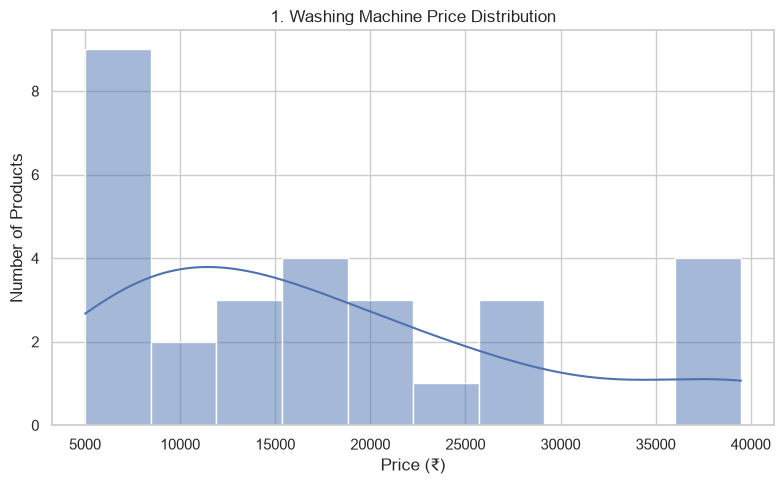

In [21]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Folder to save charts
os.makedirs("washing_machine_project/visualizations", exist_ok=True)

# Use only rows with valid values for each chart
df = clean_df.copy()

# 1. Price distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["Price"].dropna(), bins=10, kde=True)
plt.title("1. Washing Machine Price Distribution")
plt.xlabel("Price (₹)")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.savefig("washing_machine_project/visualizations/01_price_distribution.png")
plt.show()



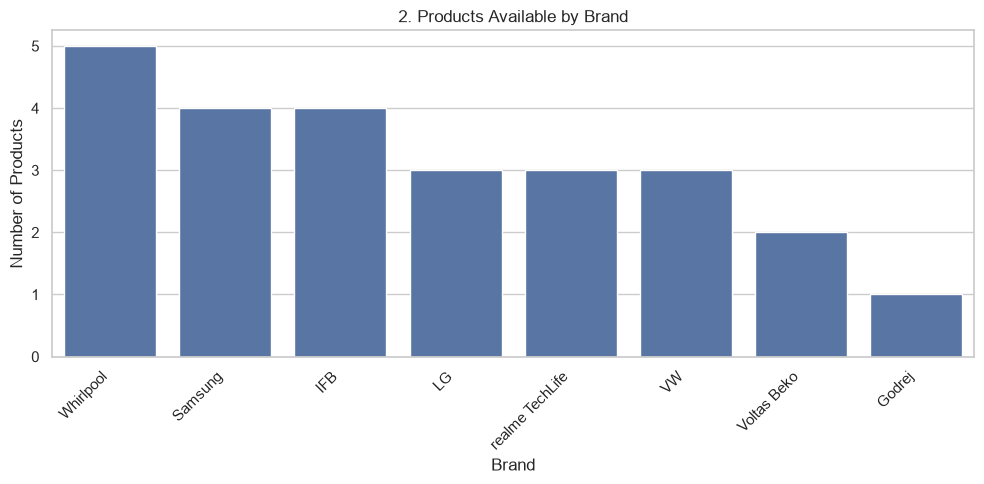

In [22]:

# 2. Number of products by brand
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df.dropna(subset=["Brand"]),
    x="Brand",
    order=df["Brand"].value_counts().index
)
plt.title("2. Products Available by Brand")
plt.xlabel("Brand")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("washing_machine_project/visualizations/02_brand_count.png")
plt.show()



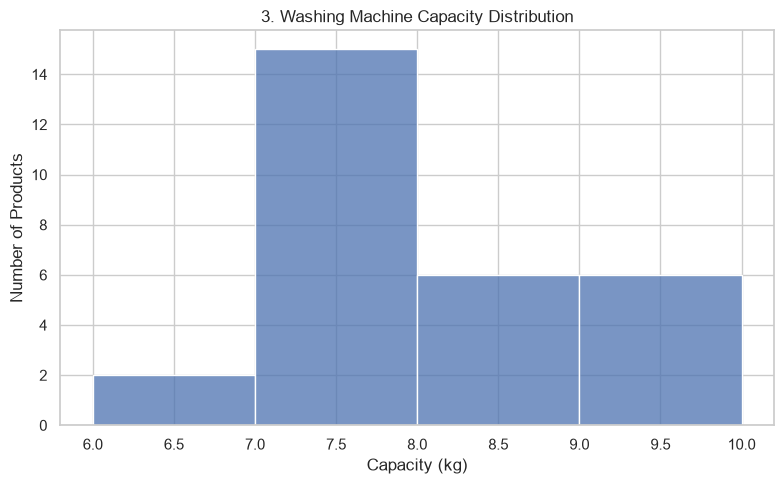

In [23]:
# 3. Capacity distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["Capacity_kg"].dropna(), bins=8, discrete=True)
plt.title("3. Washing Machine Capacity Distribution")
plt.xlabel("Capacity (kg)")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.savefig("washing_machine_project/visualizations/03_capacity_distribution.png")
plt.show()

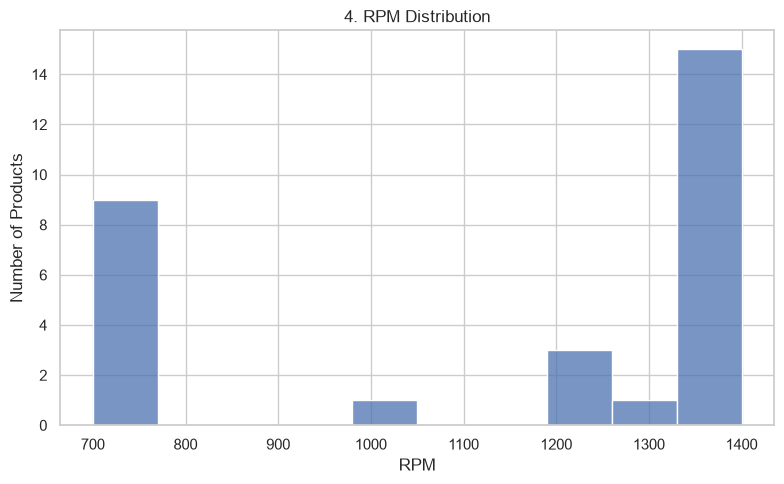

In [24]:
# 4. RPM distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["RPM"].dropna(), bins=10)
plt.title("4. RPM Distribution")
plt.xlabel("RPM")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.savefig("washing_machine_project/visualizations/04_rpm_distribution.png")
plt.show()

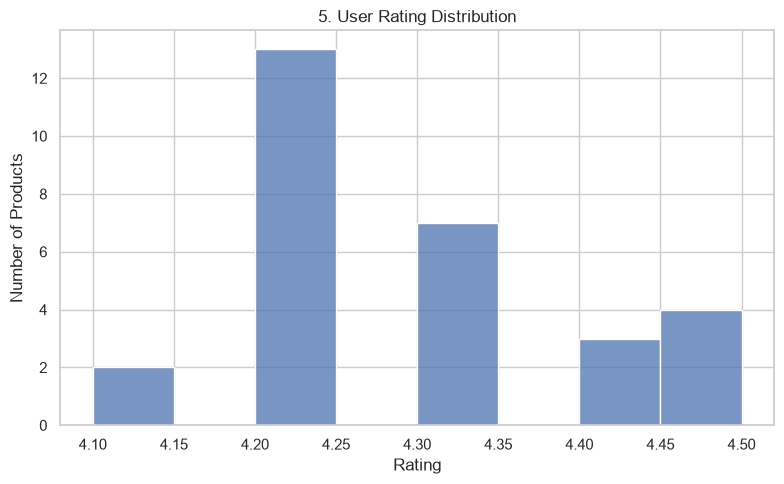

In [25]:
# 5. User rating distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["Rating"].dropna(), bins=8)
plt.title("5. User Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.savefig("washing_machine_project/visualizations/05_rating_distribution.png")
plt.show()

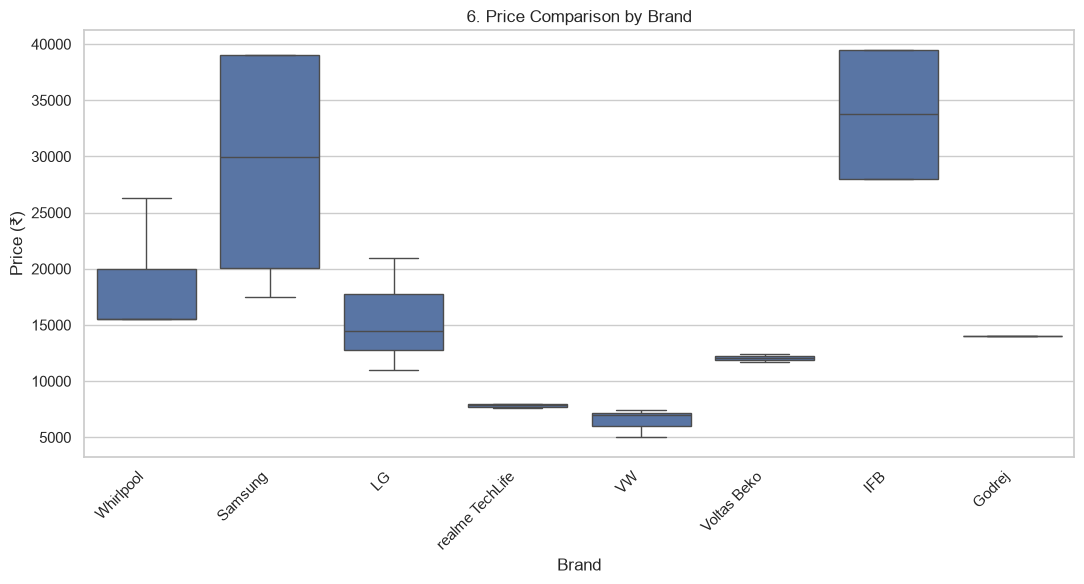

In [26]:
# 6. Price comparison by brand
brand_data = df.dropna(subset=["Brand", "Price"])

plt.figure(figsize=(11, 6))
sns.boxplot(data=brand_data, x="Brand", y="Price")
plt.title("6. Price Comparison by Brand")
plt.xlabel("Brand")
plt.ylabel("Price (₹)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("washing_machine_project/visualizations/06_price_by_brand.png")
plt.show()


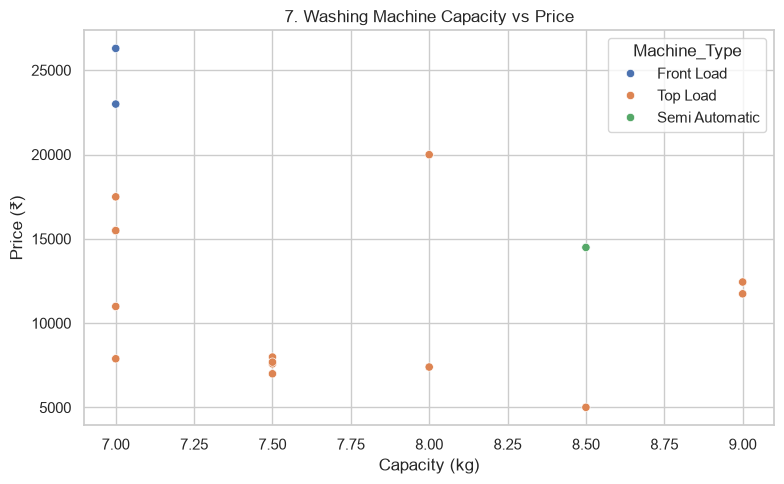

In [27]:
# 7. Capacity versus price
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df.dropna(subset=["Capacity_kg", "Price"]),
    x="Capacity_kg",
    y="Price",
    hue="Machine_Type"
)
plt.title("7. Washing Machine Capacity vs Price")
plt.xlabel("Capacity (kg)")
plt.ylabel("Price (₹)")
plt.tight_layout()
plt.savefig("washing_machine_project/visualizations/07_capacity_vs_price.png")
plt.show()

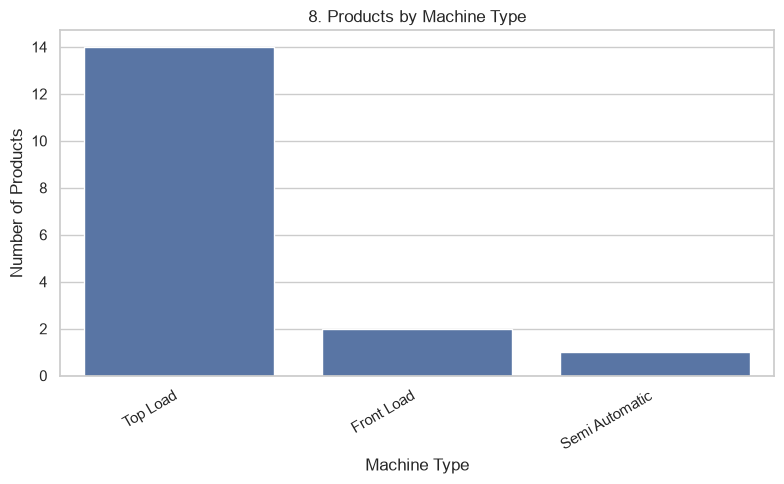

In [28]:
# 8. Machine type comparison
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df.dropna(subset=["Machine_Type"]),
    x="Machine_Type",
    order=df["Machine_Type"].value_counts().index
)
plt.title("8. Products by Machine Type")
plt.xlabel("Machine Type")
plt.ylabel("Number of Products")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("washing_machine_project/visualizations/08_machine_type.png")
plt.show()

# Step 8.2 — Perform numerical analysis

In [17]:
print("Numerical summary:")
display(
    clean_df[["Price", "Capacity_kg", "RPM", "Rating"]]
    .describe()
    .round(2)
)

print("\nAverage price by brand:")
display(
    clean_df.groupby("Brand", observed=True)["Price"]
    .agg(["count", "mean", "min", "max"])
    .round(2)
    .sort_values("mean")
)

print("\nAverage price by machine type:")
display(
    clean_df.groupby("Machine_Type", observed=True)["Price"]
    .agg(["count", "mean"])
    .round(2)
)

Numerical summary:


,Price,Capacity_kg,RPM,Rating
count,29.00,29.00,29.00,29.00
mean,17839.59,7.69,1138.28,4.28
std,10898.99,0.85,291.67,0.12
min,5010.00,6.50,700.00,4.10
25%,7890.00,7.00,740.00,4.20
50%,15490.00,7.50,1350.00,4.20
75%,22990.00,8.50,1350.00,4.30
max,39490.00,9.00,1400.00,4.50



Average price by brand:


,count,mean,min,max
Brand,,,,
VW,3,6469.33,5010,7399
realme TechLife,3,7823.33,7590,7990
Voltas Beko,2,12090.00,11740,12440
Godrej,1,13990.00,13990,13990
LG,3,15490.00,10990,20990
Whirlpool,5,18550.00,15490,26290
Samsung,4,29115.00,17490,38990
IFB,4,33740.00,27990,39490



Average price by machine type:


,count,mean
Machine_Type,,
Front Load,2,24640.00
Semi Automatic,1,14490.00
Top Load,14,11014.14


# Step 8.3 — Multivariate analysis

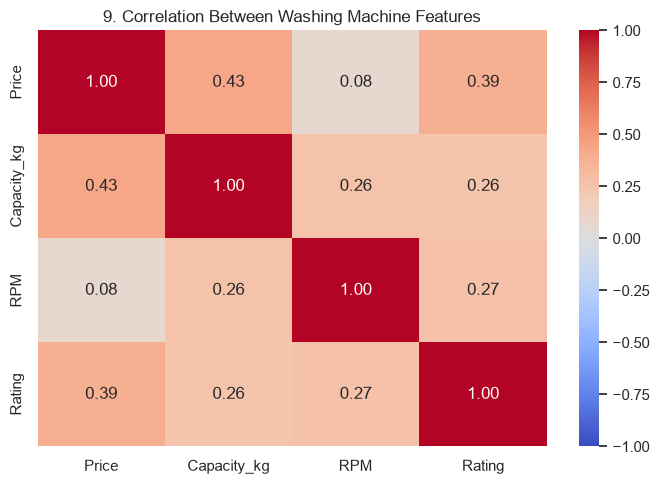

In [18]:
numeric_cols = ["Price", "Capacity_kg", "RPM", "Rating"]

correlation = clean_df[numeric_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("9. Correlation Between Washing Machine Features")
plt.tight_layout()
plt.savefig(
    "washing_machine_project/visualizations/09_correlation_heatmap.png"
)
plt.show()

# Step 9 — Answer the 10 business questions

In [19]:
print("1. What is the average washing machine price?")
print(round(clean_df["Price"].mean(), 2))

print("\n2. Which product has the highest price?")
display(clean_df.loc[clean_df["Price"].idxmax(),
                     ["Product_Name_Raw", "Price", "Brand"]])

print("\n3. Which product has the lowest price?")
display(clean_df.loc[clean_df["Price"].idxmin(),
                     ["Product_Name_Raw", "Price", "Brand"]])

print("\n4. Which brand has the most products in this dataset?")
display(clean_df["Brand"].value_counts().head(1))

print("\n5. What is the average price by brand?")
display(clean_df.groupby("Brand")["Price"].mean().round(2))

print("\n6. What is the average price by capacity?")
display(clean_df.groupby("Capacity_kg")["Price"].mean().round(2))

print("\n7. What is the average price by machine type?")
display(clean_df.groupby("Machine_Type")["Price"].mean().round(2))

print("\n8. Which products have the highest user ratings?")
display(
    clean_df.nlargest(5, "Rating")[
        ["Product_Name_Raw", "Brand", "Rating", "Price"]
    ]
)

print("\n9. What is the average RPM?")
print(round(clean_df["RPM"].mean(), 2))

print("\n10. What is the average price for each power rating?")
display(clean_df.groupby("Power_Rating")["Price"].mean().round(2))

1. What is the average washing machine price?
17839.59

2. Which product has the highest price?


Product_Name_Raw    IFB 9 kg with 9 Swirl Wash, 2x Power Steam, 30...
Price                                                           39490
Brand                                                             IFB
Name: 10, dtype: object


3. Which product has the lowest price?


Product_Name_Raw    VW 8.5 kg Semi-Automatic Top Load Washer only ...
Price                                                            5010
Brand                                                              VW
Name: 6, dtype: object


4. Which brand has the most products in this dataset?


Brand
Whirlpool    5
Name: count, dtype: int64

... (6 outputs left out)


8. Which products have the highest user ratings?


,Product_Name_Raw,Brand,Rating,Price
4,"LG 7 kg 5 Star with Wind Jet Dry, Collar Scrub...",LG,4.5,10990
13,"IFB 7 kg with 9 Swirl Wash, 2x Power Steam, 30...",IFB,4.5,27990
17,LG 8.5 kg 5 Star with Roller Jet Pulsator with...,LG,4.5,14490
24,"1. IFB 7 kg with 9 Swirl Wash,... 4.5 3,842 Ra...",IFB,4.5,27990
8,"LG 8 kg 5 Star, Smart Inverter Technology, Tur...",LG,4.4,20990



9. What is the average RPM?
1138.28

10. What is the average price for each power rating?


Power_Rating
5    18297.79
Name: Price, dtype: float64

# Business Insights — Washing Machine Market Analysis

1. Price Variation: Washing machine prices vary across products depending on brand, capacity, features, and machine type.

2. Brand Comparison: Different brands have different price ranges. Comparing average prices helps identify budget-friendly and premium brands.

3. Capacity and Price: Washing machines with higher capacities may cost more because they can handle larger laundry loads.

4. Popular Capacity: The most frequently listed capacity in the dataset can help identify which capacity range is commonly offered in the market.

5. Machine Type: Top-load, front-load, and semi-automatic machines may have different price ranges and customer preferences.

6. Rating Analysis: Product ratings help compare customer feedback across available washing machines and brands.

7. RPM Comparison: RPM (revolutions per minute) helps compare the spin speeds of different washing machines.

8. Missing Product Information: Some listings do not provide complete warranty or machine-type information. This limits comparisons based on these features.

# Business Recommendations — Washing Machine Market Analysis

1. Offer Products at Different Price Points: Businesses should maintain budget, mid-range, and premium washing machines to serve customers with different budgets.

2. Choose Popular Capacities: Stock more products in the capacity ranges that appear most frequently in the collected dataset, while checking customer demand before making inventory decisions.

3. Compare Competitor Pricing: Regularly compare prices across brands to identify competitive pricing opportunities.

4. Highlight Product Ratings: Display verified customer ratings clearly to help buyers compare products and make informed decisions.

5. Improve Product Information: Include complete details about warranty, capacity, RPM, machine type, and energy ratings wherever available.

6. Use Discounts Strategically: Analyze discount levels and product prices to plan promotions that attract customers without unnecessarily reducing profit margins.

7. Promote Products by Customer Needs: Highlight suitable products for different needs, such as budget-conscious buyers, larger families, and customers looking for particular machine types.

8. Update Market Data Regularly: Repeat the web-scraping process periodically to track price changes, discounts, newly listed products, and changes in product availability.

9. Focus on Underrepresented Brands: Investigate brands with fewer listings to determine whether expanding their product selection would offer a business opportunity.

10. Use Data for Inventory Planning: Combine price, capacity, brand, ratings, and customer-demand data to make better purchasing and stock-management decisions.